# `triplicate_noise.ipynb`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
experiment = '10.22.2025_07.07_AM'
file = f'../experiments/{experiment}/final_data.csv'

In [9]:
df = pd.read_csv(file)

# Remove controls
df = df[~df['fish'].str.contains('ctrl', case=False, na=False)]

In [10]:
import pandas as pd

# Group by barcode, fish, sample and aggregate
summary = (
    df.groupby(['barcode', 'fish', 'sample'])
      .agg(
          mean_proportion=('proportion', 'mean'),
          std_proportion=('proportion', 'std'),
          n_replicates=('replicate', 'count')
      )
      .reset_index()
)

In [111]:
N = 100

fake_df = []
for i in range(10):
    p = np.random.uniform()

    replicates = np.random.binomial(N, p, size = 3) / N

    d = {}
    d['mean_proportion'] = np.mean(replicates)
    d['std_proportion'] = np.std(replicates)
    d['n_replicates'] = 3

    fake_df.append(d)

fake_df = pd.DataFrame(fake_df)

In [114]:
import numpy as np
from scipy.optimize import minimize_scalar

def mle_N_from_proportions(df):
    # Filter out rows with only one replicate (no variance)
    df = df[df['n_replicates'] > 1].copy()

    p = df['mean_proportion'].values
    s2 = df['std_proportion'].values**2
    n = df['n_replicates'].values

    def neg_log_likelihood(N):
        if N <= 0:
            return np.inf
        var_model = p * (1 - p) / N
        return np.sum(n * (np.log(var_model) + s2 / var_model))

    result = minimize_scalar(neg_log_likelihood, bounds=(1e-3, 1e6), method='bounded')
    return result.x

# Example usage
N_mle = mle_N_from_proportions(summary[summary['std_proportion'] > 0])
print(f"Estimated shared Binomial N (MLE): {N_mle:.2f}")

Estimated shared Binomial N (MLE): 371.38


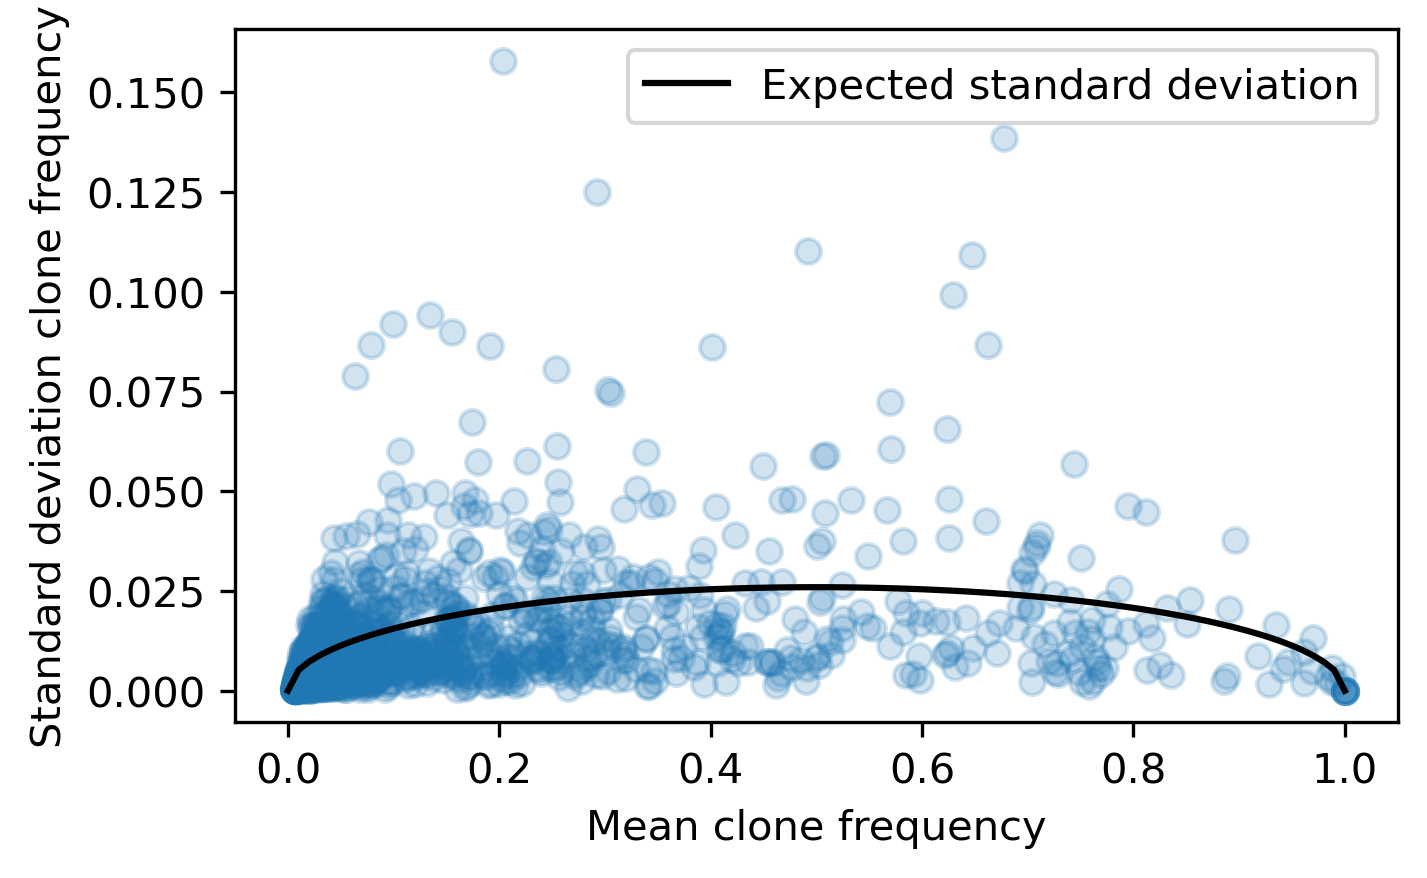

In [136]:
fig, ax = plt.subplots(figsize = (5, 3), dpi = 300)
ax.scatter(summary['mean_proportion'], summary['std_proportion'], alpha = 0.2)

ps = np.linspace(0, 1, 100)
ax.plot(ps, np.sqrt((ps*(1-ps))/N_mle), color = 'black', label = 'Expected standard deviation')

ax.set_xlabel('Mean clone frequency')
ax.set_ylabel('Standard deviation clone frequency')
ax.legend()